<a href="https://colab.research.google.com/github/itgery/statistics_lab/blob/main/Math.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="lab01-sprint-1"></a>
# Lab01 - sprint 1

<a id="dataset-description"></a>
## Dataset

**Описание датасета:**

Название: BUPA Liver Disorders  
Автор: BUPA Medical Research Ltd.   
Размер: 345 наблюдений, 7 полей.

**Поля:**

1)  mean — средний объём эритроцита
2) alkphos — щелочная фосфатаза
3) sgpt — аланинаминотрансфераза
4) sgot  — аспартатаминотрансфераза |
5) gammagt — γ-глутамилтранспептидаза
6) drinks — количество алкогольных напитков, в эквиваленте пол-пинт (284 мл), которые человек выпивает в день
7) selector — техническое поле, использованное авторами для разделения на обучающую и тестовую выборки


**Источник:** UCI Machine Learning Repository, Liver Disorders, DOI: `10.24432/C54G67`.


**Пролог — Королевство Печени**  
 Далеко за горами Средних Значений и лесами Доверительных Интервалов находилось Королевство Печени. В нём жили 345 жителей, а сведения о каждом были записаны в древней Книге BUPA. На каждой странице хранились биохимические показатели, сведения об употреблении алкоголя и загадочный знак `selector`. Исследовательницам предстояло понять, что означают эти числа, какие из них связаны между собой и где заканчивается статистика и начинается домысел.


**Ссылка на датасет в OpenML: https://www.openml.org/search?type=data&status=active&id=8&sort=runs**

In [ ]:
#@title Environment setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.io import arff
import gzip
import base64
import io

sns.set_style("whitegrid")  # сетка на графиках
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [ ]:
#@title Helper function
def describe_rv(series):
    s = pd.Series(series).dropna().astype(float)
    return pd.Series({
        "n": len(s),
        "mean": s.mean(),
        "median": s.median(),
        "variance_unbiased": s.var(ddof=1),
        "std_unbiased": s.std(ddof=1),
        "min": s.min(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "max": s.max(),
        "skewness": stats.skew(s, bias=False),
        "excess_kurtosis": stats.kurtosis(s, fisher=True, bias=False),
        "unique_values": s.nunique(),
    })

def ecdf_xy(series):
    x = np.sort(pd.Series(series).dropna().to_numpy(dtype=float))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def z_standardize(series):
    s = pd.Series(series, dtype=float)
    return (s - s.mean()) / s.std(ddof=1)

def minmax_normalize(series):
    s = pd.Series(series, dtype=float)
    return (s - s.min()) / (s.max() - s.min())

def population_sample_table(population, sample):
    pop = pd.Series(population, dtype=float)
    smp = pd.Series(sample, dtype=float)
    out = pd.DataFrame({
        "population": [
            pop.mean(),
            pop.var(ddof=0),
            pop.median(),
            pop.quantile(0.25),
            pop.quantile(0.75),
        ],
        "sample": [
            smp.mean(),
            smp.var(ddof=1),
            smp.median(),
            smp.quantile(0.25),
            smp.quantile(0.75),
        ],
    }, index=["mean", "variance", "median", "Q1", "Q3"])
    out["absolute_difference"] = (out["sample"] - out["population"]).abs()
    return out

def consistency_experiment(series, sample_sizes=(20, 50, 100, 150, 250, 300),
                           repeats=1000, seed=2026):
    arr = np.asarray(series, dtype=float)
    mu = arr.mean()
    var = arr.var(ddof=0)
    rng = np.random.default_rng(seed)
    rows = []

    for n in sample_sizes:
        mean_err = []
        var_err = []

        for _ in range(repeats):
            sample = rng.choice(arr, size=n, replace=False)
            mean_err.append(abs(sample.mean() - mu))
            var_err.append(abs(sample.var(ddof=1) - var))

        rows.append([n, np.mean(mean_err), np.mean(var_err)])

    return pd.DataFrame(rows, columns=["n", "MAE_mean", "MAE_variance"])

def distribution_fit_table(series):
    x = np.asarray(series, dtype=float)

    candidates = {
        "Normal": (stats.norm, {}),
        "Lognormal": (stats.lognorm, {"floc": 0}),
        "Gamma": (stats.gamma, {"floc": 0}),
        "Weibull": (stats.weibull_min, {"floc": 0}),
    }

    rows = []
    fitted = {}

    for name, (dist, kwargs) in candidates.items():
        params = dist.fit(x, **kwargs)
        fitted[name] = (dist, params)
        loglik = np.sum(dist.logpdf(x, *params))
        k = len(params)
        aic = 2*k - 2*loglik

        # KS statistic is reported descriptively.
        # Its ordinary p-value is not treated as an exact formal test
        # because parameters are estimated on the same sample.
        ks_stat = stats.kstest(x, dist.cdf, args=params).statistic
        rows.append([name, aic, ks_stat, params])

    table = pd.DataFrame(
        rows,
        columns=["distribution", "AIC", "KS_statistic_descriptive", "MLE_params"]
    ).sort_values("AIC")

    return table, fitted

## Data loading

Датасет встроен в ноутбук в сжатом формате (gzip + base64) для обеспечения автономной работы.

In [ ]:
ARFF_GZ_B64 = """H4sIAEGr22oC/31ZW28UVxJ+hl9xXhC7UuP0uZ/mYRWSeBESQQgSKfvYtht7xMy0d7rHLFrtf9+qr86ljUjQJNg1dc6pe9VXPFP6Qv22W/fTS/XT7+9fqf3uYTqpm90yn26m0/L0maKPuVAf5/PpelK746f5dBjX3Xx8SV/Qnxcv1M+naVzn05Kv+HW62V2Pe/VhWqbxdH2n3q43F5X5l/k4n16qD7vru/F0oz5eqH/S0a/rnXC0P0m9Ps3Lw0Ts6hX9dZ6+5fh1vL+fTvvpq3o/nj5/++27eV13x9u78aDevbbK//LHtxx96M2LYHSIoYk3rmQK/4OmzzD0or+9oBeWVZ2X8Za+rczv5uOkPh/nL0c1r3dkt/VuPKovd+Oqdota7viL3ZGok3r/8w8/Xb56/fZS/b5Mp+eLen3e3TSN/vbltFvX6aiuvn7HNH+/EDncBRl1Pz2Mx/X7nviNXvq0O5GoXj2Mp914tZ8WNZ4mNe736mo/zzdqnZZ1ISHpFXyz3s3n27u1irLO6mpSy3RcdisFA//+TVCwmqs67OgU3bBb6M3TfKgXTP+5npaFj4776/lu3qvr+bicD/cs64VSlyO9vN8dp2Kbq/P9eHEzriPJvm824VPrbj2TwGA7Tdf0vpo/qVEt5Nn9pA7jnm+52T3sbs7jvkXZG5KMgmMswt6cdsfPyz88/DIfSL/5tOaryKLXFL5qZmnoe5bkalymiyrJx2n6CycqcoQ6zKdH2ZE95i/Uu/PhiqxHb+1In/FIxnmprPPCELYM47qedles8EsV1UxGJ7cJX7xQr8q33/E9ZfHh+uHJYaL4Iyvdn5fr8348qYd5fz5kk1IWj/vP93fz8oT+HuEB/o3+W0ldYaJQX27vV+IYD8zA/5/X03hcPpE0hcsx17yqJ+NyP55Wypk/YST9b8fDYbxdn+DvF7f78zoevu4VWO8nCoqbyk3GEEc9OVab3I37Ty/udxTx07/Puwdy+JHCl40lwbW7pnBlS91Oy7cJTn9uTufjZ3XP4Tt+le/JlNXnFHHT/oYSe7rhQF/u97sVAUA2pt/XL0Sb1lwG04X6dbdw6FFy7c/spSNVgGf01ZvmETVezecV8cIX0XH6/ue3rz5+/O1f7y/5CFlq3Bfim3e/XP7xUu2pvjx99vTpj6dpL9cg6V60Svz0xxoe6jk5+7l68+63y9eXHx59kT38/S/Zs3/2zfwn32T3ff9L8dZz9eHy1dvH92UDP1f/1Z35HwnPtniafDeYzvnOxM7qrr/oO83E4Do/dNZ0xoJonqbQeddZ22n8IMRBdzF11nWGvgqFM3aRrqGzqdN94Uyd952m45E/mTN1gdh6pgxE8/w40WJndKfxESLJSG8a8MZC67tAl9CPQ+fLYfrR8Cskj65Ew6/Iu5XIp10XNOuobeEMXYz5Sp0KZ4BAA+SsAkFxopDRKie9zpwwERTPxDiU10M7rvvI5+njK5WE5qMaZt7qTq4Q4xUrDZbfIaJc8cgilp3pN9InFpFVqjZ2Xeo7F/mdIbZ3yG1sOLogtCuJjR3pN3qSiwJe1k1PqCRm3shJseA0jDQ07dnMAy4NEgv5vEcMkvzONDXJIeyixB6oz5NWdJyed32zXfAcIazq1ktEocAjGyS51HB4UzCJ9qYQSSBLIjoWdGiM9KFwIHPYvhDJyYgvdn4qRMdpRI9Y0tdtOBPODkUjEHWPmDG+BB6Si65g0V0xE54PeF67YntJGViTbV+Oc4iEfFYXQQdSs0fc4odMJIt4SG+KmehOy3YUzqYSxS2sIfHcRHLfHufXI9OpAgz1IbIwPMHurGpGTk8D+ZtBRU3LAuT0hEETOIW56u6Qhvx6Ieb0DDB0kZMzQZyETyVSoSOnc72Kjcgh4jYBDitRzJAIGxNrVBb/2HBU6aSCDHyjluo5oIggQTjqCzFwUnJ6ONAkDjUYHYwMou4te0gMpAtV9CE3sDncI6KBh8gBBg8xMaJaoGYIkeTkhI0s/NAYo5hCo7AKI2p7zuzQOJOo4jiO65VsTyu1QVjhjCh1H/Kb0iTImoguXRk96ieKbWM0yA2SyaI6C5VruuYqQlJSSNU7B2SVNKRMpKaFqqCRdvVSKor8Bhfx+FesHF9SFQLMWs/Db8Z3GxoXMJNbghWLULxY2I50K7SEEoB+xvFZjOxSLtyFRsqEAeFpWNZ2OiA0EHm2RpKB5rjAFhd5pBrLWR/Xub9RUfIWRFgzSU5zc3aNGlDmiGpDJrKWPmeWqZyeu5HxWdHKGWBKCtikN3eiwHJmUKjUWEI1YwlsJnJB96XtukKU+EXnJa3ycc2haGNucpWo+wGRgByuVPEbe6O+g66LGuJFJEniwHIiSCstSYux6DKFyOEfsp1diZmErml8I5KWlAkUx467Xr0UlYrHGuorhdNw6dVDzjlXbBwwE0m2u2JOulaXUHQ1tTDUcOEPhRhQvVLuO0KMue8gPoxtgmoSUyPnt09FtBOOWtcUHaTaoEvX8wHeffS+4cpicNyljaQeFkUnzndaDvnazOqd0ng02ky9M4RclcjRXlxsEWGIWvr4kl1R8niAt72cR1/WWh4k3/viUo+uw8+ZQgzMmydQ3zgD+quBt32RyktuI9B9lR+5wWFSL6UE9zIGDnxvPc+Vtc/dIohW8L5BSJKxQo1mm0cRkikTMdhaSEBZW4976Rxuw9mzRy1e9/WhwILGPnfO9rphVSlyYnj0kJHZsv8rkRImEe5ACRNRVRNlgKtILERpaZJQOhMTJqghR3TIHVHGWlStWKiEJ5wMwJYrZ6hwhKpwhI5x83qEnzz7NRMt9w8rSZqaSNEUH9U7I+JeQ/HUjrORU876etzLTI8Yra+z5TW70m3U9BJzGAfCtl46aDpsjg/sIyrjVDhjcQcLkNDmGRGVbEjoahT75K1YpKcJxaBZ0fySSqcapF4OLGsq0eCkv1tO31SnCYNAxCSW6vMyrNJDG8aIWZ3D2xXq917nuJEO4jmnUzUozCF1KBXlB4zgaJd9oaJ2S354W4iaBaUrWPl+c97mNNKk1lDEjyjvGZj0pWwESTmHgG6oFeWOwoSMUqie09ZjRmE/9m16Sei0FgYyNX5MFoLbgSn6irE4J3tGQiIbZoiE90zPMVeGrShABA2hL93Mh9LJTSE6BnQO0WpNwd5E1Mi/fgOAY0HFtoFFUwBPL1dm+Owww3BSmobBKNM4rP3mSg+l+tw6GlpzuUinDS7rc5aZeqXF7Pn4HfR2D3gSGlAWAGkFmLrGyk1XJnS72QgkxDTx2Q34zx1qi7N7rhN6yIPI9jhjBrPBvz5D+tS2FvS/PPNuMC01Ig51JIvdGIT7Up68Y3tI5+Yeuw0kzwuFremlkxtcsdWeByuNWXEDiplVwsHbDYwKOSu3uFLT72y+LVqleETL5lHPbyAT9iPaN3DF/VFG4tDwEQ1gwebpRm9gGHdSk4tfw+Ro4mYLgBOnghNdQ4PKZFaGkRiEM9EgHCGqS43TY5w16PIVl3qgeZ0aCJT+YAUmlDsHhLim6xiPbS+IdfpNDUGHlMtXrLjYIkGRtbYYn/0RMKYK7qoQOpTEs1tcXTYC202Bx+LEWNnNFQgNiKA3Gw3mRHab/vFxl/cZjQgjW1tiqpZprF5MKDi0zN+CyXXlNHntlOeoehwlSANG13lNZkDEqK6dA1MZeZ6zqExbg8kWsrEQLZaN8rgurDKw5Fyu0BjthJXqsYaQ89gpOOSyTQ3HRtG9fwSDncs7RJ0aMQgmkMytRVhkwoKvYXA0fApRu+EMQ96wZWwrPTvmVmoq3pY7Zegor5M9ncuDLru+Qhefx7rYN2g76FyJjG/QNvmy5ugbsmbglPliu9RLcZUiVQ2a8gSoU7vUt2mtvh6QGAYGsUX4iMoky5OGWcv+UofGGWT2jgUwV1zu82CViYaHNYvSlrboNHELdVga2Ao9gM+kvrlq5D4vILzdIDQUFoHrFQ0xlhLhKxrCtk9iZmhoJvZ5fGwIC0O23FcBHha9GJeoQPiKcQSc6Nw+G3EoG4T6EqYRKuIcyUNDWKGs111oYEoGGC27yQpkJVXtBrVplDCX11bVIB4dgSfNfoPlksgdm/TSVTQWbN43JOtl+MGqqcFLk8tN5Rxkr2DzqrrayXFZQeLqZhOMAjZlLF5hl5eyEhuU4wt8DrAtFHOmGHkoRIv1tUO7tbGdj7psgDeoLdq8R9RbgMhbZZ2BSgNOMtC4Mugj9LDmkpWQaawUhx61aKjE2IkN6JMqEb9qnf8lphJDyqNGxi4YyCwMpYcNFhw6aSI86/e2CRV47MUqUTdZv4tQA3dGyR1XgY4vOCliCC/xwxVGb8Es4sehAzEeHDJSYevzqOXkH1ZsJieBsyYvx+Nm7WFt3o1VXOEFbKEdpGIWSj95zRZUkxB3ZBkZ9lL1irG5vtuCdRLWQlJzXcUlHuOjgPx8AQb91OcZoOISBq9JULLD6qPuUjRimOe6AGACrTT5yvm8OMnIhFdEGvVYemHFK9pUIRo00ewFuta6yizrLIShzLuNmsuP3cKYoWz9EM3aFJdT9/KIPHZOgTEJRQzDIXcTX4u4bD3zP0oUA/MSBLWHxwDR4/+mpYY/8CIAAA=="""

raw_text = gzip.decompress(base64.b64decode(ARFF_GZ_B64)).decode("utf-8")
data, meta = arff.loadarff(io.StringIO(raw_text))
df = pd.DataFrame(data)

display(df.head())

,mcv,alkphos,sgpt,sgot,gammagt,drinks,selector
0,85.0000,92.0000,45.0000,27.0000,31.0000,0.0000,b'1'
1,85.0000,64.0000,59.0000,32.0000,23.0000,0.0000,b'2'
2,86.0000,54.0000,33.0000,16.0000,54.0000,0.0000,b'2'
3,91.0000,78.0000,34.0000,24.0000,36.0000,0.0000,b'2'
4,87.0000,70.0000,12.0000,28.0000,10.0000,0.0000,b'2'


In [ ]:
print(f"Размер: {df.shape}")
print(f"Пропуски: {df.isna().sum().sum()}")
print(f"Дубликаты: {df.duplicated().sum()}")

Размер: (345, 7)
Пропуски: 0
Дубликаты: 4


В датасете нет пропущенных значений, но есть несколько полностью совпадающих строк. Они сохраняются, поскольку работа анализирует опубликованный UCI-набор в его исходном объёме.

<a id="dataset-research-object"></a>
## Research Object

**Выбранные случайные величины:**

- $X_1(\omega)=\mathrm{drinks}(\omega)$ — число эквивалентов половины пинты алкоголя в день;
- $X_2(\omega)=\mathrm{gammagt}(\omega)$ — γ-глутамилтранспептидаза;
- $X_3(\omega)=\mathrm{sgot}(\omega)$ — аспартатаминотрансфераза.

Выбор сделан так, чтобы одновременно исследовать поведенческий показатель употребления алкоголя и два биохимических показателя крови.

<a id="rv01"></a>
## Random Variable 01 — drinks

Первая случайная величина:

$X_1(\omega)=\mathrm{drinks}(\omega)$.

Она показывает, сколько алкоголя человек в среднем выпивает за день. За одну условную порцию принимается половина пинты, то есть примерно 0,24 литра напитка.

Значение `drinks`  для конкретного человека значение фиксировано, но при случайном выборе человека заранее неизвестно, поэтому это **случайная величина**. В датасете она принимает конечный набор значений, поэтому рассматривается как **дискретная**.

### EDA & Distribution




In [ ]:
#@title EDA
display(drinks.describe().to_frame()) #описательная статистика для drinks

,drinks
count,345.0000
mean,3.4551
std,3.3378
min,0.0000
25%,0.5000
50%,3.0000
75%,6.0000
max,20.0000


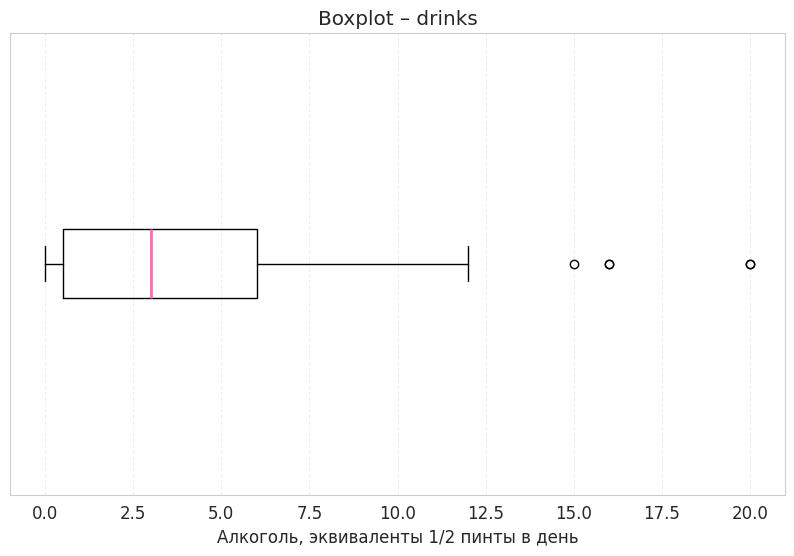

In [ ]:
plt.boxplot(drinks, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.title("Boxplot – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

### Интерпретация описательной статистики

В выборке из 345 пациентов:

- **Среднее потребление** составило 3.46, медиана - 3.0 (правосторонняя асимметрия).
- **Межквартильный размах** (IQR = Q₃ − Q₁ = 5.5) показывает, что центральные 50% пациентов употребляют от 0.5 до 6.0 порций в день.
- **Разброс значений** огромный: от 0 до 20 порций в день.
- **Коэффициент асимметрии** ≈ 1.54 подтверждает выраженную правостороннюю асимметрию: большинство пациентов пьют умеренно, но есть небольшая группа с аномально высоким потреблением.

**Вывод:** Распределение `drinks` не является симметричным и, скорее всего, не подчиняется нормальному закону.

### Distribution
Для дискретной величины эмпирическая вероятность значения $x_j$:

$P(X_1=x_j)=n_j/N$,

где $n_j$ — число наблюдений с данным уровнем употребления алкоголя.

Математическое ожидание:

$E[X_1]=\sum_j x_jp_j$.

Дисперсия:

$D[X_1]=\sum_j(x_j-E[X_1])^2p_j$.

In [ ]:
drinks_pmf = drinks.value_counts().sort_index().rename("count").to_frame()
drinks_pmf["probability"] = drinks_pmf["count"] / len(drinks)
display(drinks_pmf)

x, y = ecdf_xy(drinks)


,count,probability
drinks,,
0.0000,9,0.0261
0.5000,108,0.3130
1.0000,17,0.0493
2.0000,35,0.1014
3.0000,21,0.0609
4.0000,50,0.1449
5.0000,17,0.0493
6.0000,40,0.1159
7.0000,6,0.0174


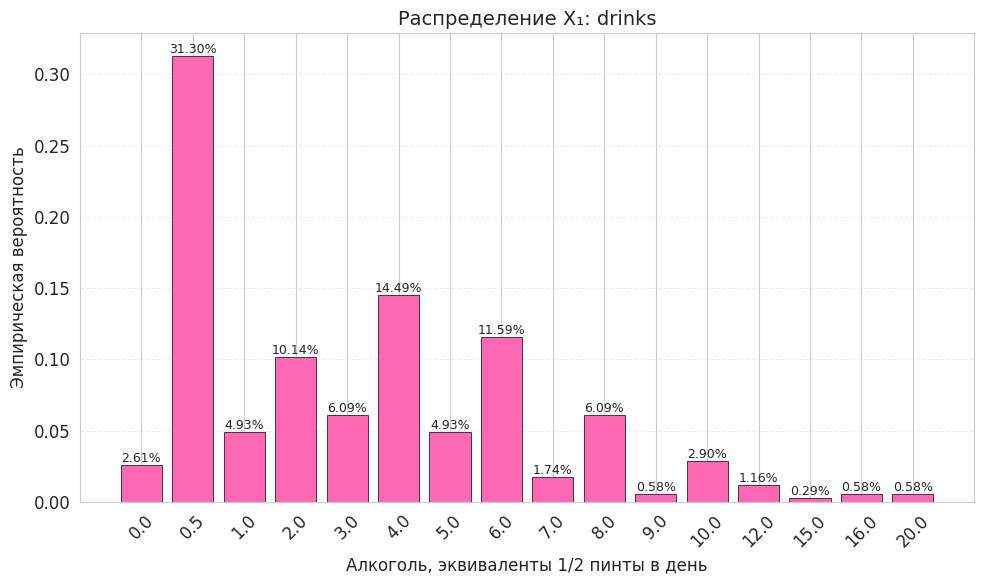

In [ ]:
pmf = drinks.value_counts(normalize=True).sort_index()

bars = plt.bar(pmf.index.astype(str), pmf.values,
               color='hotpink', edgecolor='black', linewidth=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2%}', ha='center', va='bottom', fontsize=9)

plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.ylabel("Эмпирическая вероятность")
plt.title("Распределение X₁: drinks", fontsize=14)
plt.grid(axis="y", alpha=0.3, linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

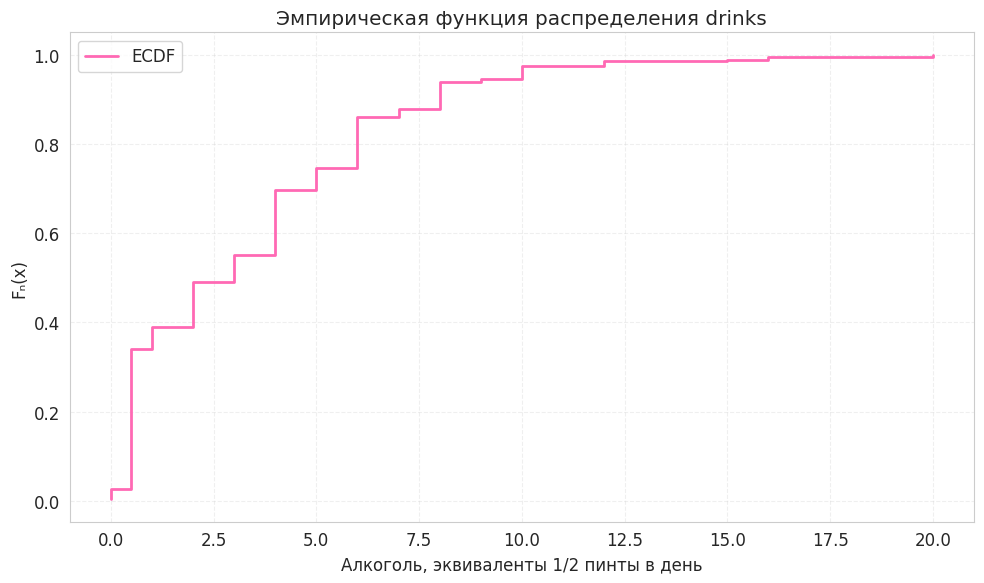

In [ ]:
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.ylabel("Fₙ(x)")
plt.title("Эмпирическая функция распределения drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

#### Normalization / Standardization

Z-стандартизация:

$Z_i=\frac{X_i-\bar X}{s}$.

Мы используем значения с разными единицами измерения, стандартизация приводит все к общему виду.

Min-Max нормализация:

$X_i'=\frac{X_i-X_{\min}}{X_{\max}-X_{\min}}$.

Она переводит наблюдаемые значения в интервал $[0,1]$.

Оба преобразования изменяют масштаб, но **не делают исходное распределение нормальным**.

In [ ]:
drinks_z = z_standardize(drinks)
drinks_mm = minmax_normalize(drinks)

display(pd.DataFrame({
    "original": drinks,
    "z_score": drinks_z,
    "minmax": drinks_mm
}).head(10))

print("Z mean:", round(drinks_z.mean(), 10))
print("Z std:", round(drinks_z.std(ddof=1), 10))
print("Min-Max range:", drinks_mm.min(), drinks_mm.max())

,original,z_score,minmax
0,0.0000,-1.0351,0.0000
1,0.0000,-1.0351,0.0000
2,0.0000,-1.0351,0.0000
3,0.0000,-1.0351,0.0000
4,0.0000,-1.0351,0.0000
5,0.0000,-1.0351,0.0000
6,0.5000,-0.8853,0.0250
7,0.5000,-0.8853,0.0250
8,0.5000,-0.8853,0.0250
9,0.5000,-0.8853,0.0250


Z mean: 0.0
Z std: 1.0
Min-Max range: 0.0 1.0


### Independence & Estimations

Так как `drinks`, `gammagt` и `sgot` измерены у одного и того же человека, проверяется статистическая связь между ними.

Для монотонной связи используется коэффициент Спирмена:

$H_0:\rho_s=0$, монотонной связи между двумя величинами нет.

$H_1:\rho_s\ne0$, между величинами есть монотонная связь.

In [ ]:
gammagt = df["gammagt"].astype(float)
sgot = df["sgot"].astype(float)

pairs = [
    ("drinks ↔ gammagt", drinks, gammagt),
    ("drinks ↔ sgot", drinks, sgot),
    ("gammagt ↔ sgot", gammagt, sgot),
]

rows = []
for name, a, b in pairs:
    pear = stats.pearsonr(a, b)
    spear = stats.spearmanr(a, b)
    rows.append([
        name,
        pear.statistic, pear.pvalue,
        spear.statistic, spear.pvalue,
    ])

dependence_table = pd.DataFrame(
    rows,
    columns=[
        "pair",
        "Pearson_r", "Pearson_p",
        "Spearman_rho", "Spearman_p",
    ]
)
display(dependence_table)

,pair,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,drinks ↔ gammagt,0.3412,0.0000,0.3415,0.0000
1,drinks ↔ sgot,0.2796,0.0000,0.2548,0.0000
2,gammagt ↔ sgot,0.5276,0.0000,0.4654,0.0000


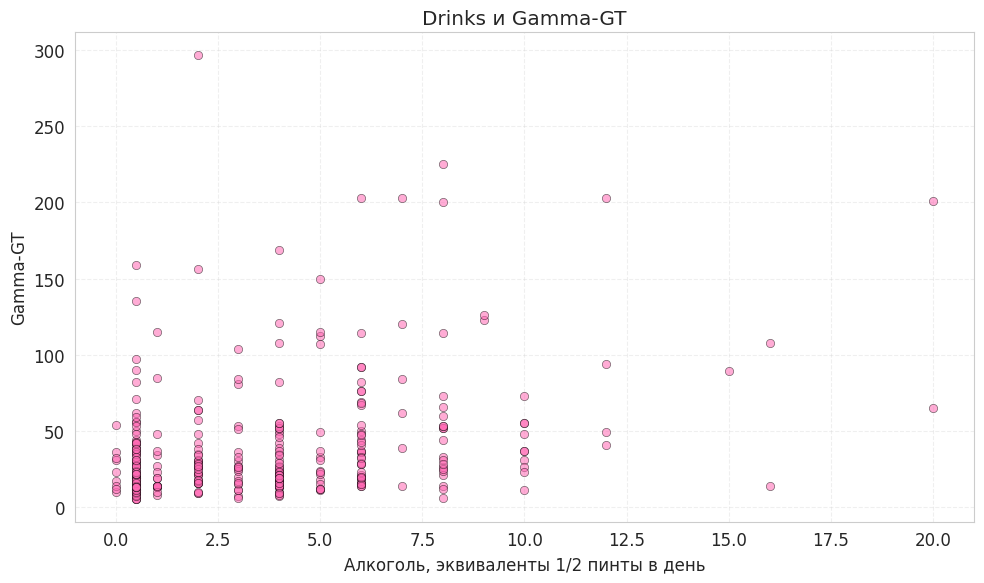

In [ ]:
plt.scatter(drinks, gammagt, color='hotpink', alpha=0.55, edgecolors='black', linewidth=0.5)
plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.ylabel("Gamma-GT")
plt.title("Drinks и Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

Получено:

- `drinks ↔ gammagt`: Spearman $\rho_s\approx0.342$, $p<0.001$;
- `drinks ↔ sgot`: Spearman $\rho_s\approx0.255$, $p<0.001$;
- `gammagt ↔ sgot`: Spearman $\rho_s\approx0.465$, $p<0.001$.

Монотонная связь отсутствует. Наиболее выраженная из выбранных пар — связь Gamma-GT и SGOT. Корреляция не доказывает причинно-следственную связь.

#### Population vs Sample

Все 345 наблюдений датасета рассматриваются как генеральная совокупность. Из неё берётся случайная выборка объёмом n = 100.

**Выборка без возвращения** — каждый пациент может попасть в выборку только один раз. Это естественный сценарий: нельзя опросить одного человека дважды.

**Выборка с возвращением** — один пациент может быть выбран несколько раз. Используется для сравнения и демонстрации метода бутстрапа.

In [ ]:
rng = np.random.default_rng(42)

idx_without = rng.choice(df.index.to_numpy(), size=100, replace=False)
sample_without = df.loc[idx_without]

idx_with = rng.choice(df.index.to_numpy(), size=100, replace=True)
sample_with = df.loc[idx_with]

print("Число уникальных индексов без возвращения:", len(np.unique(idx_without)))
print("Число уникальных индексов с возвращением:", len(np.unique(idx_with)))

display(population_sample_table(drinks, sample_without["drinks"]))

Число уникальных индексов без возвращения: 100
Число уникальных индексов с возвращением: 89


,population,sample,absolute_difference
mean,3.4551,3.6900,0.2349
variance,11.1089,15.8827,4.7739
median,3.0000,3.0000,0.0000
Q1,0.5000,0.5000,0.0000
Q3,6.0000,5.0000,1.0000


#### Consistency of Estimations

Оценка $\hat\theta_n$ называется состоятельной, если при росте $n$ она сходится по вероятности к истинному параметру:

$\hat\theta_n\xrightarrow{P}\theta$.

Эмпирически проверяем это для среднего и дисперсии: многократно строим выборки увеличивающегося объёма и считаем среднюю абсолютную ошибку относительно параметров полной конечной совокупности.

In [ ]:
cons_drinks = consistency_experiment(drinks)
display(cons_drinks)

,n,MAE_mean,MAE_variance
0,20,0.5858,4.3564
1,50,0.3545,2.8863
2,100,0.2219,1.7965
3,150,0.1601,1.2925
4,250,0.0901,0.7285
5,300,0.0541,0.4638


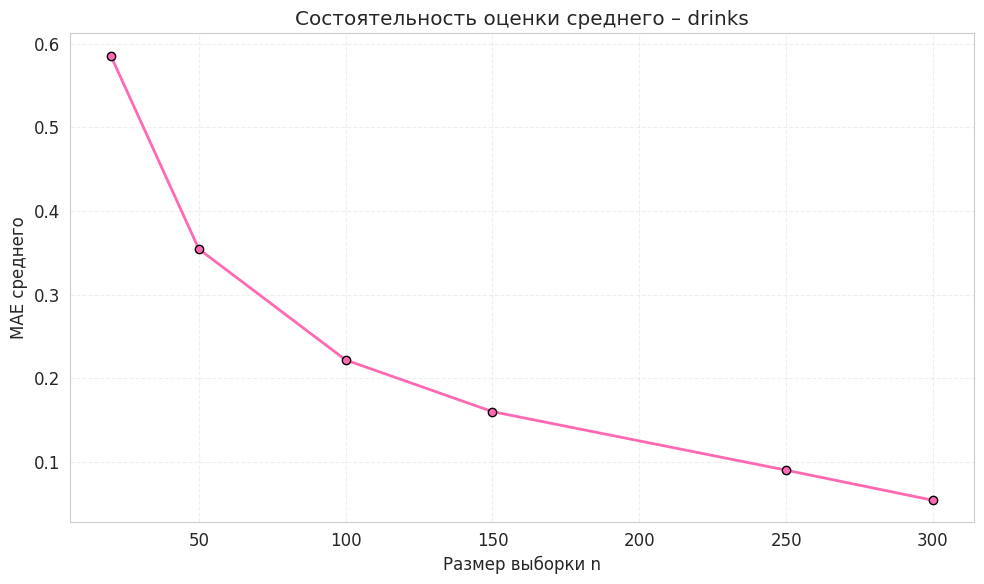

In [ ]:
cons_drinks = consistency_experiment(drinks)

plt.plot(cons_drinks["n"], cons_drinks["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

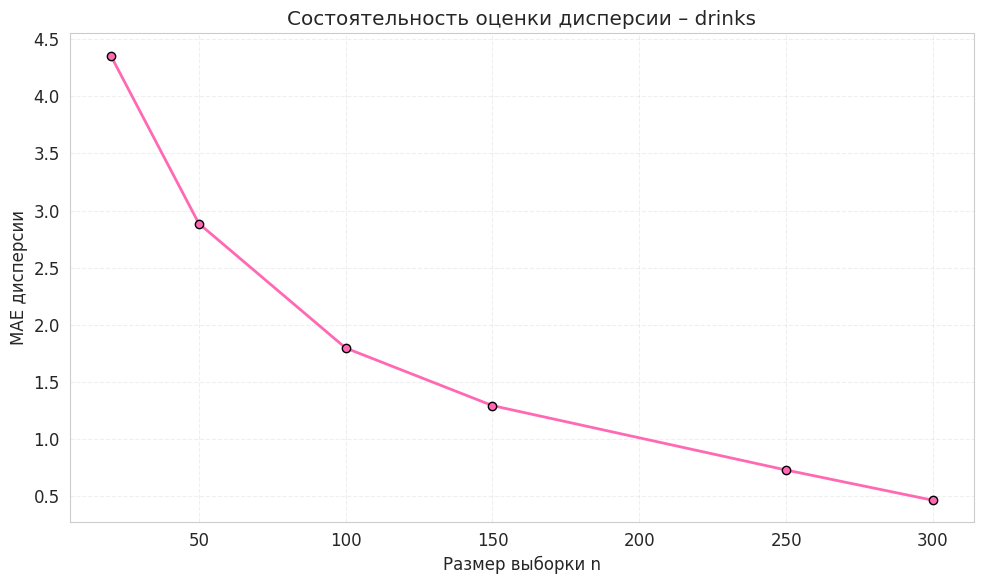

In [ ]:
plt.plot(cons_drinks["n"], cons_drinks["MAE_variance"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE дисперсии")
plt.title("Состоятельность оценки дисперсии – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

При увеличении $n$ средняя абсолютная ошибка уменьшается. Это является **эмпирической иллюстрацией состоятельности** оценок для данной конечной совокупности.

In [ ]:
display(population_sample_table(
    gammagt,
    sample_without["gammagt"]
))

,population,sample,absolute_difference
mean,38.2841,40.4500,2.1659
variance,1536.4584,1465.7652,70.6933
median,25.0000,25.0000,0.0000
Q1,15.0000,16.0000,1.0000
Q3,46.0000,53.5000,7.5000


In [ ]:
cons_g = consistency_experiment(gammagt)
display(cons_g)

,n,MAE_mean,MAE_variance
0,20,7.0878,930.2019
1,50,4.0728,570.8540
2,100,2.5900,369.1726
3,150,2.0150,280.5196
4,250,1.0748,145.9534
5,300,0.6256,89.2471


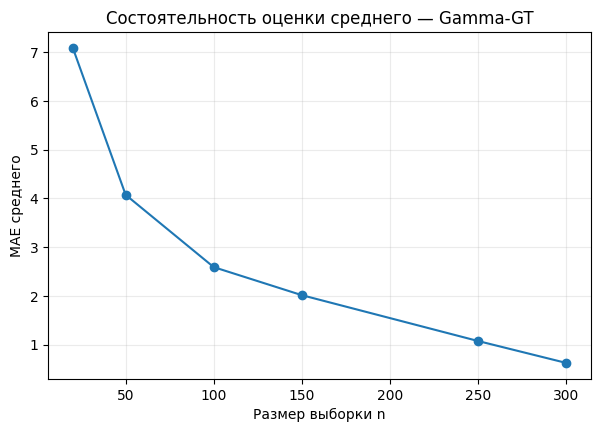

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.plot(cons_g["n"], cons_g["MAE_mean"], marker="o")
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего — Gamma-GT")
plt.grid(alpha=0.25)
plt.show()

<a id="rv02"></a>
## Random Variable 02 — Gamma-GT


Вторая случайная величина:

$X_2(\omega)=\mathrm{gammagt}(\omega)$.

`gammagt` — показатель γ-глутамилтранспептидазы (Gamma-GT, GGT) в анализе крови.

#### Стохастическая природа

При случайном выборе человека заранее неизвестно, какое у него значение Gamma-GT. Это зависит от биологических показателей конкретного человека и не вычисляется из номера записи.

В датасете результаты представлены целыми числами, однако по природе это количественная величина, получаемая лабораторным измерением.

### EDA & Distribution

In [ ]:
display(describe_rv(gammagt).to_frame("gammagt"))

,gammagt
n,345.0000
mean,38.2841
median,25.0000
variance_unbiased,1540.9249
std_unbiased,39.2546
min,5.0000
Q1,15.0000
Q3,46.0000
IQR,31.0000
max,297.0000


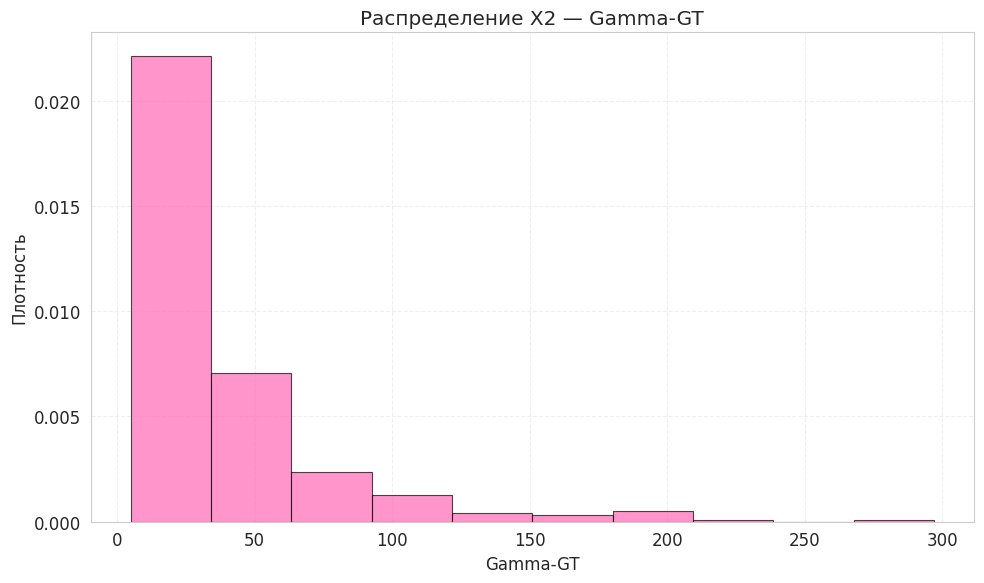

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(gammagt, bins="sturges", density=True,
         color='hotpink', edgecolor='black', linewidth=0.8, alpha=0.7)
plt.xlabel("Gamma-GT")
plt.ylabel("Плотность")
plt.title("Распределение X2 — Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

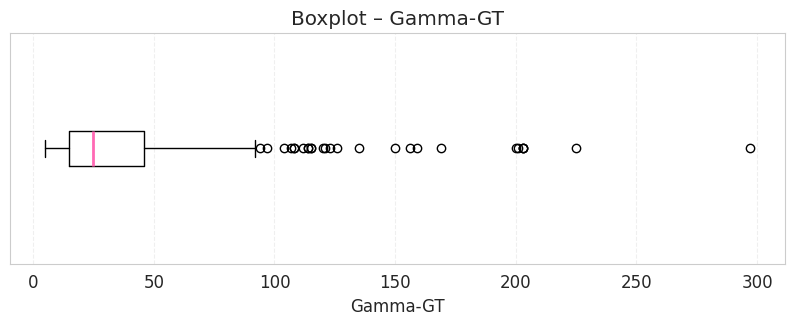

In [ ]:
plt.figure(figsize=(10, 3))
plt.boxplot(gammagt, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("Gamma-GT")
plt.title("Boxplot – Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

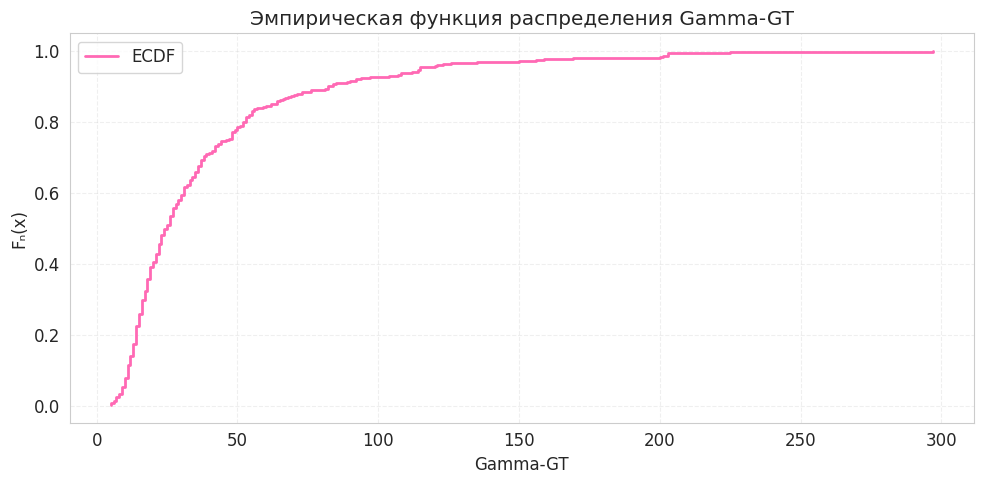

In [ ]:
x, y = ecdf_xy(gammagt)

plt.figure(figsize=(10, 5))
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("Gamma-GT")
plt.ylabel("Fₙ(x)")
plt.title("Эмпирическая функция распределения Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

**Интерпретация.**

- среднее — окло **38.28**;
- медиана — **25**;
- минимум — **5**, максимум — **297**;
- коэффициент асимметрии около **2.87**.

Среднее существенно выше медианы, высокий коэффициент ассиметрии, что в свою очередь указывает на выраженный правый хвост.

#### Normality hypothesis

**Проверяем гипотезу:**

$H_0:$ Gamma-GT имеет нормальное распределение.

$H_1:$ распределение Gamma-GT не является нормальным.

Используем критерий Шапиро–Уилка при уровне значимости $\alpha=0.05$.

In [ ]:
shapiro_g = stats.shapiro(gammagt)

print(f"Shapiro W = {shapiro_g.statistic:.6f}")
print(f"p-value = {shapiro_g.pvalue:.3e}")

Shapiro W = 0.683938
p-value = 6.481e-25


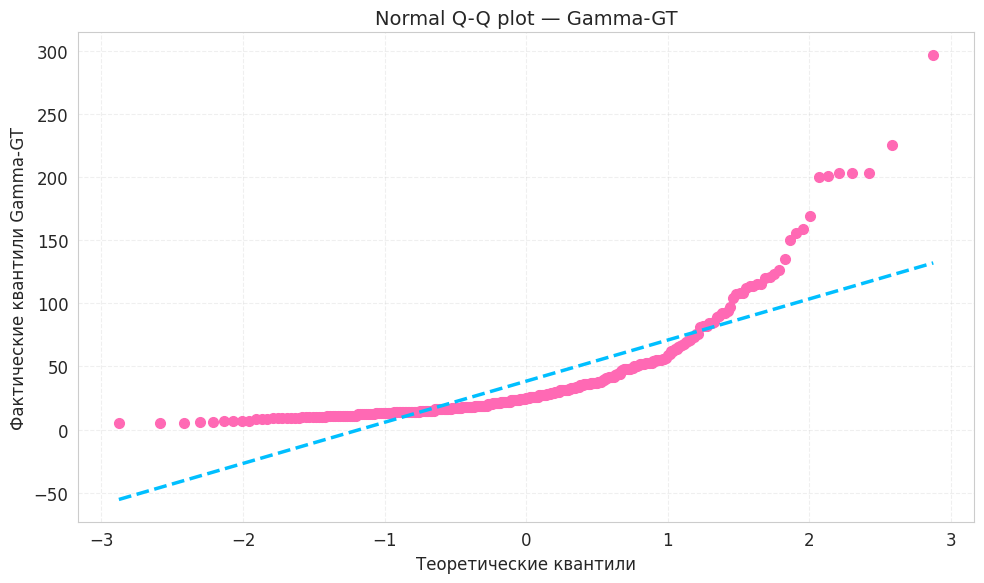

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

stats.probplot(gammagt, dist="norm", plot=ax)

lines = ax.get_lines()
lines[0].set_color('hotpink')
lines[0].set_marker('o')
lines[0].set_markersize(7)
lines[0].set_markeredgecolor('hotpink')
lines[0].set_markerfacecolor('hotpink')
lines[0].set_linestyle('None')

lines[1].set_color('deepskyblue')
lines[1].set_linewidth(2.5)
lines[1].set_linestyle('--')

ax.set_title("Normal Q-Q plot — Gamma-GT", fontsize=14)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Фактические квантили Gamma-GT")
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

Значение $p$-value значительно меньше 0.05, поэтому гипотеза $H_0$ ложна: распределение не является нормальным.

Для снижения выбросов дополнительно проверим логарифмическое преобразование:

$Y=\ln(X_2)$.

In [ ]:
log_gammagt = np.log(gammagt)
print("Skewness original:", round(stats.skew(gammagt, bias=False), 4))
print("Skewness log:", round(stats.skew(log_gammagt, bias=False), 4))

Skewness original: 2.8661
Skewness log: 0.5169


In [ ]:
shapiro_log_g = stats.shapiro(log_gammagt)
print(f"Shapiro log W = {shapiro_log_g.statistic:.6f}")
print(f"Shapiro log p-value = {shapiro_log_g.pvalue:.3e}")

Shapiro log W = 0.977403
Shapiro log p-value = 3.072e-05


Логарифмирование резко уменьшает асимметрию, но тест Шапиро–Уилка всё равно отвергает нормальность при $\alpha=0.05$.

Получаем, что логарифмирование улучшает форму распределения, но по прежнему не гарантирует нормальность.

#### Mathematical distribution model

Для нашей величины сравниваем четыре модели: Normal, Lognormal, Gamma и Weibull.

Для сравнения используем информационный критерий Акаике:

$AIC=2k-2\ln L$;

где $k$ — число параметров, $L$ — максимизированное правдоподобие.

Чем меньше AIC тем лучше модель, но это не доказывает истинность распределения.

In [ ]:
fit_g, fitted_g = distribution_fit_table(gammagt)
display(fit_g)

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,3094.0728,0.0703,"(0.7787867291737537, 0, 27.290735903010912)"
2,Gamma,3168.5895,0.1161,"(1.6238065666838846, 0, 23.576735527802224)"
3,Weibull,3192.4444,0.1175,"(1.187437894589408, 0, 40.998927670937654)"
0,Normal,3514.4138,0.2072,"(38.28405797101449, 39.1976841344471)"


,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,3094.0728,0.0703,"(0.7787867291737537, 0, 27.290735903010912)"
2,Gamma,3168.5895,0.1161,"(1.6238065666838846, 0, 23.576735527802224)"
3,Weibull,3192.4444,0.1175,"(1.187437894589408, 0, 40.998927670937654)"
0,Normal,3514.4138,0.2072,"(38.28405797101449, 39.1976841344471)"


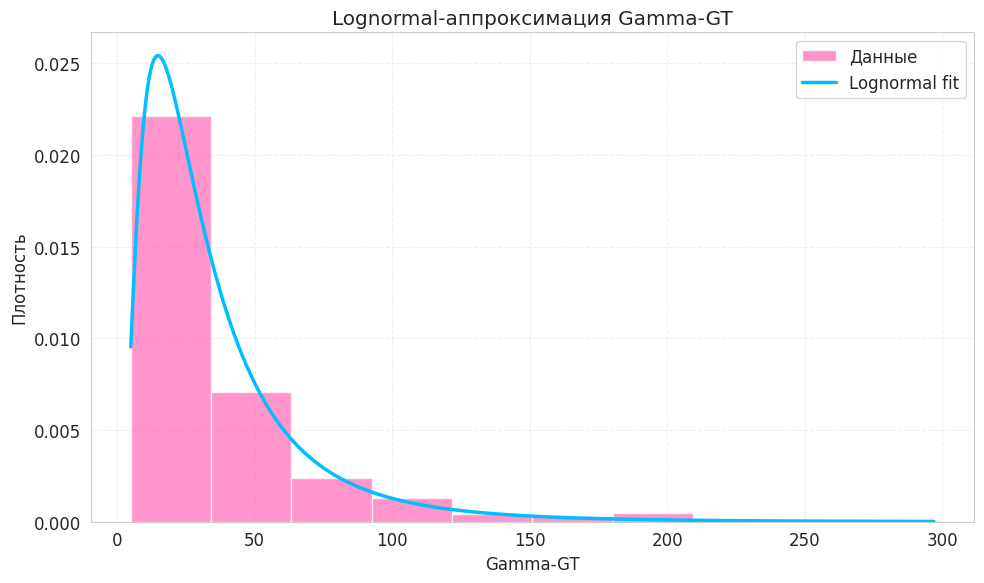

In [ ]:
table_g, fitted_g = distribution_fit_table(gammagt)
display(table_g)

grid = np.linspace(gammagt.min(), gammagt.max(), 600)

plt.figure(figsize=(10, 6))
plt.hist(gammagt, bins="sturges", density=True,
         color='hotpink', alpha=0.7, label="Данные")

dist_g, params_g = fitted_g["Lognormal"]
plt.plot(grid, dist_g.pdf(grid, *params_g),
         color='deepskyblue', linewidth=2.5, label="Lognormal fit")

plt.xlabel("Gamma-GT")
plt.ylabel("Плотность")
plt.title("Lognormal-аппроксимация Gamma-GT")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

Среди рассмотренных моделей наименьший AIC получает **Lognormal**.

Если

$\ln X\sim N(\mu,\sigma^2)$,

то плотность логнормального распределения:

$f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln x-\mu)^2}{2\sigma^2}\right),\quad x>0$.

Для этих данных получаем аппроксимацию $\mu\approx3.31$ и $\sigma\approx0.78$.

#### Normalization / Standardization

Приведём данные к нулевому среднему и единичной дисперсии:

In [ ]:
g_z = z_standardize(gammagt)
print(f"Z mean: {g_z.mean():.10f}")
print(f"Z std:  {g_z.std(ddof=1):.10f}")

Z mean: 0.0000000000
Z std:  1.0000000000


Также масштабируем значения в отрезок $[0, 1]$:

In [ ]:
g_mm = minmax_normalize(gammagt)
print(f"Min-Max range: [{g_mm.min():.4f}, {g_mm.max():.4f}]")

Min-Max range: [0.0000, 1.0000]


### Independence & Estimations

Для GGT уже показана статистически значимая связь с `drinks` и с `sgot`.

Теперь сравним параметры полной совокупности и случайной выборки, и эмпирически исследуем состоятельность оценок.

In [ ]:
display(population_sample_table(
    gammagt,
    sample_without["gammagt"]
))

,population,sample,absolute_difference
mean,38.2841,40.4500,2.1659
variance,1536.4584,1465.7652,70.6933
median,25.0000,25.0000,0.0000
Q1,15.0000,16.0000,1.0000
Q3,46.0000,53.5000,7.5000


In [ ]:
cons_g = consistency_experiment(gammagt)
display(cons_g)

,n,MAE_mean,MAE_variance
0,20,7.0878,930.2019
1,50,4.0728,570.8540
2,100,2.5900,369.1726
3,150,2.0150,280.5196
4,250,1.0748,145.9534
5,300,0.6256,89.2471


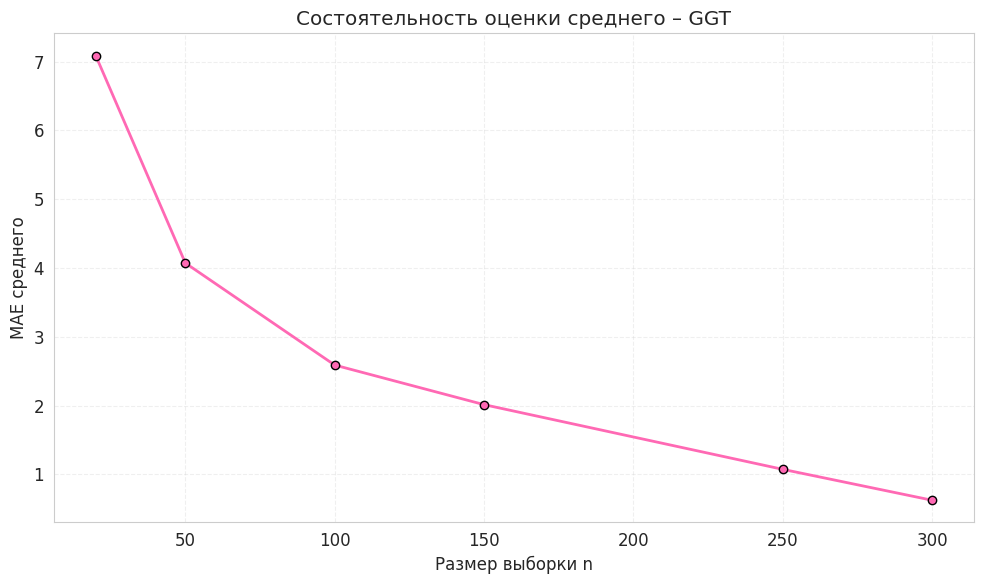

In [ ]:
cons_g = consistency_experiment(gammagt)

plt.figure(figsize=(10, 6))
plt.plot(cons_g["n"], cons_g["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – GGT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

   Как видно из графика, с ростом размера выборки $n$ средняя абсолютная ошибка оценки среднего стремится к нулю. Это эмпирическое подтверждение свойства состоятельности выборочного среднего.

<a id="rv03"></a>
## Random Variable 03 — SGOT

### Description

Третья случайная величина:

$X_3(\omega)=\mathrm{sgot}(\omega)$.

`sgot` — показатель аспартатаминотрансферазы (AST) в анализе крови.


При случайном выборе человека заранее неизвестно значение SGOT. Величина отражает индивидуальное лабораторное измерение и не задаётся никакой формулой

### EDA & Distribution
### EDA


In [ ]:
display(describe_rv(sgot).to_frame("sgot"))

,sgot
n,345.0000
mean,24.6435
median,23.0000
variance_unbiased,101.2940
std_unbiased,10.0645
min,5.0000
Q1,19.0000
Q3,27.0000
IQR,8.0000
max,82.0000


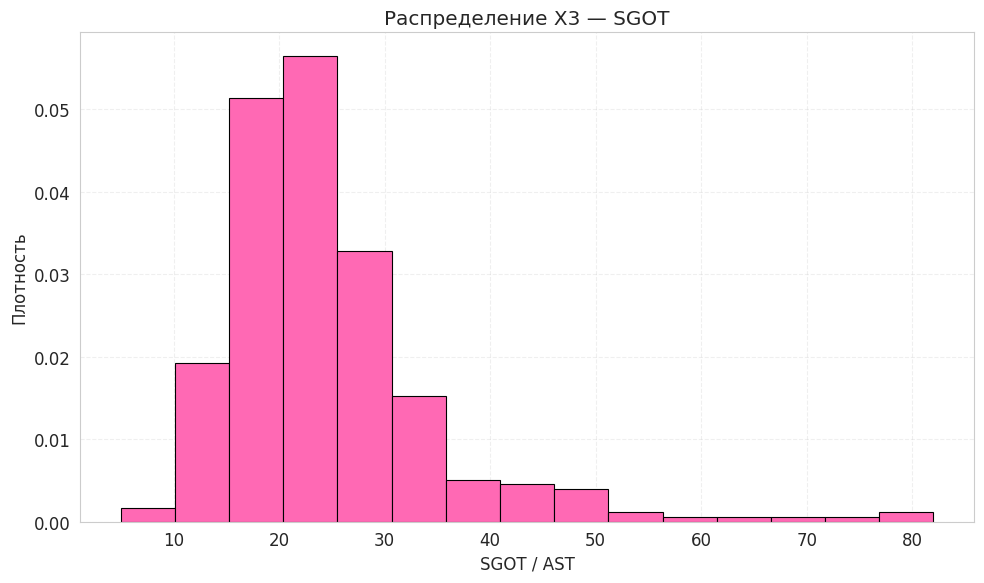

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(sgot, bins=15, density=True,
         color='hotpink', edgecolor='black', linewidth=0.8)
plt.xlabel("SGOT / AST")
plt.ylabel("Плотность")
plt.title("Распределение X3 — SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

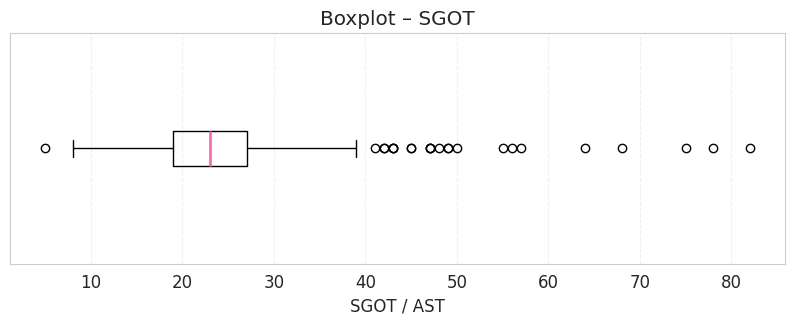

In [ ]:
plt.figure(figsize=(10, 3))
plt.boxplot(sgot, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("SGOT / AST")
plt.title("Boxplot – SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

**Интерпретация:**

В выборке из 345 пациентов:

- **Среднее значение** составляет 24.64 Ед/л, при этом **медиана** равна 23.00 Ед/л (правосторонняя асимметрия распределения).
- **Межквартильный размах** (IQR = Q₃ − Q₁ = 8) показывает, что центральные 50% пациентов имеют уровень SGOT в диапазоне от 19 до 27 Ед/л*(концентрация большинства значений вокруг медианы).
- **Разброс значений** значителен: от 5 до 82 Ед/л  
- **Коэффициент асимметрии** ≈ 2.29 свидетельствует о сильной правосторонней асимметрии: большинство пациентов имеют умеренные значения SGOT, но небольшая группа демонстрирует аномально высокие показатели.
- **Эксцесс** ≈ 8.14 указывает на острый пик распределения и тяжёлые хвосты.

**Вывод:** Распределение SGOT является выраженно правосторонне асимметричным и не подчиняется нормальному закону.

### Distribution

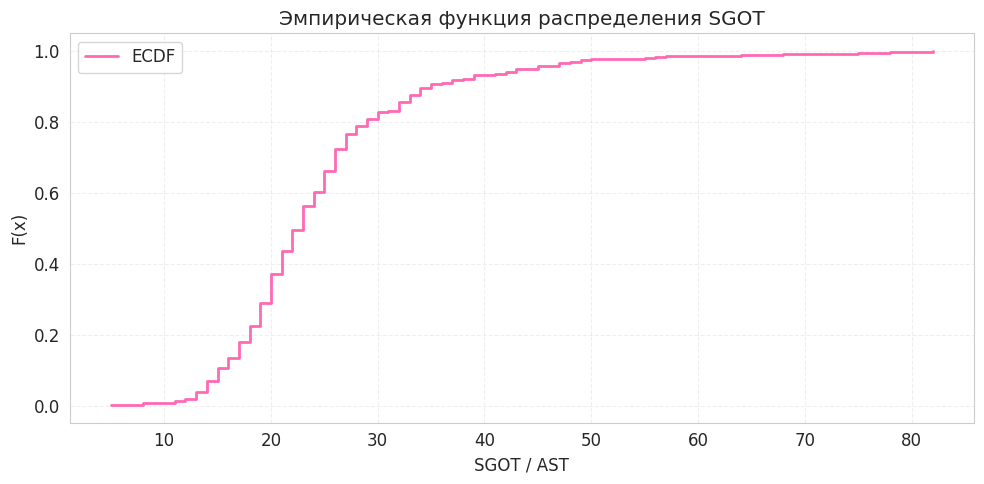

In [ ]:
x, y = ecdf_xy(sgot)

plt.figure(figsize=(10, 5))
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("SGOT / AST")
plt.ylabel("F(x)")
plt.title("Эмпирическая функция распределения SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

#### Normality hypothesis

$H_0:$ SGOT имеет нормальное распределение.

$H_1:$ SGOT не имеет нормального распределения.

In [ ]:
shapiro_s = stats.shapiro(sgot)

print(f"Shapiro W = {shapiro_s.statistic:.6f}")
print(f"p-value = {shapiro_s.pvalue:.3e}")

Shapiro W = 0.814962
p-value = 1.403e-19


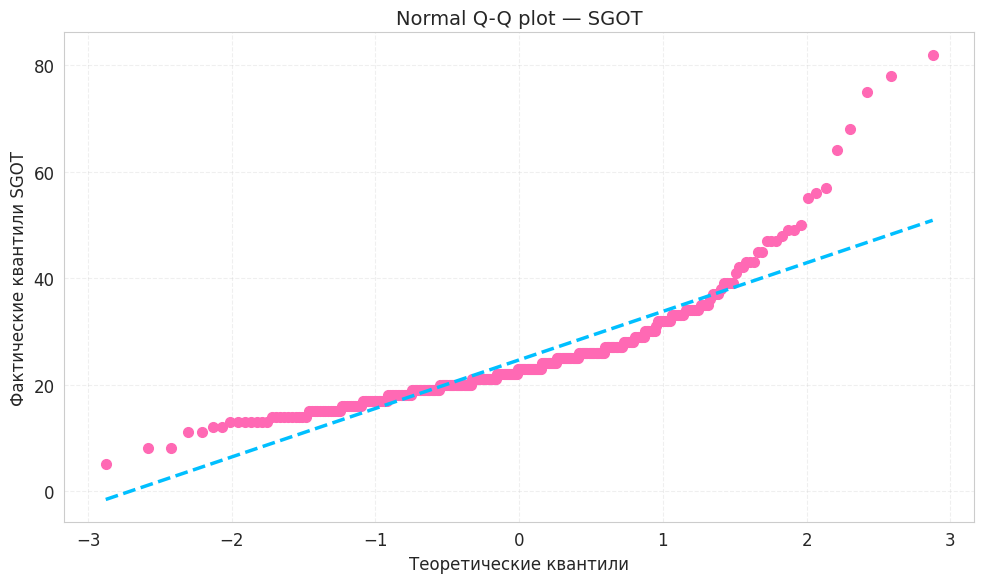

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

stats.probplot(sgot, dist="norm", plot=ax)

lines = ax.get_lines()
lines[0].set_color('hotpink')
lines[0].set_marker('o')
lines[0].set_markersize(7)
lines[0].set_markeredgecolor('hotpink')
lines[0].set_markerfacecolor('hotpink')
lines[0].set_linestyle('None')

lines[1].set_color('deepskyblue')
lines[1].set_linewidth(2.5)
lines[1].set_linestyle('--')

ax.set_title("Normal Q-Q plot — SGOT", fontsize=14)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Фактические квантили SGOT")
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

Нормальность отвергается при $\alpha=0.05$.

Проверим логарифмическое преобразование.

In [ ]:
log_sgot = np.log(sgot)

print("Skewness original:", round(stats.skew(sgot, bias=False), 4))
print("Skewness log:", round(stats.skew(log_sgot, bias=False), 4))

shapiro_log_s = stats.shapiro(log_sgot)
print(f"Shapiro log W = {shapiro_log_s.statistic:.6f}")
print(f"Shapiro log p-value = {shapiro_log_s.pvalue:.3e}")

Skewness original: 2.2931
Skewness log: 0.3366
Shapiro log W = 0.966283
Shapiro log p-value = 3.657e-07


Логарифмирование уменьшает асимметрию, однако точная нормальность также не достигается.

#### Mathematical distribution model

In [ ]:
fit_s, fitted_s = distribution_fit_table(sgot)
display(fit_s)

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,2431.0272,0.0931,"(0.35232109686943325, 0, 23.07629660667206)"
2,Gamma,2458.1680,0.1182,"(7.772523294212377, 0, 3.170589180378493)"
3,Weibull,2550.8392,0.1567,"(2.463594468362426, 0, 27.71203415229293)"
0,Normal,2575.2856,0.1725,"(24.643478260869564, 10.049896938845267)"


,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,2431.0272,0.0931,"(0.35232109686943325, 0, 23.07629660667206)"
2,Gamma,2458.1680,0.1182,"(7.772523294212377, 0, 3.170589180378493)"
3,Weibull,2550.8392,0.1567,"(2.463594468362426, 0, 27.71203415229293)"
0,Normal,2575.2856,0.1725,"(24.643478260869564, 10.049896938845267)"


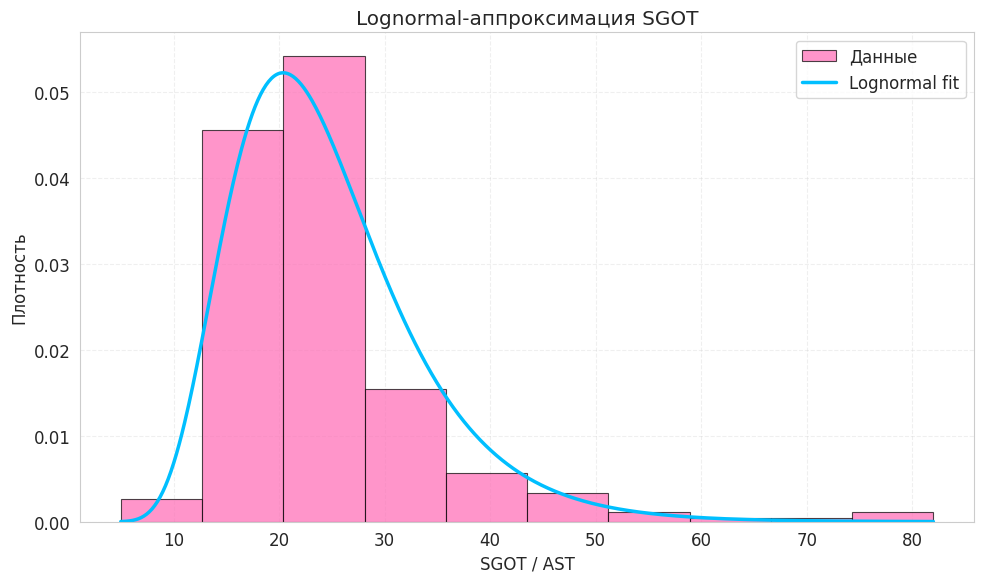

In [ ]:
table_s, fitted_s = distribution_fit_table(sgot)

display(table_s)

grid = np.linspace(sgot.min(), sgot.max(), 600)

plt.hist(sgot, bins="sturges", density=True,
         color='hotpink', edgecolor='black', linewidth=0.8, alpha=0.7, label="Данные")

dist_s, params_s = fitted_s["Lognormal"]
plt.plot(grid, dist_s.pdf(grid, *params_s),
         color='deepskyblue', linewidth=2.5, linestyle='-', label="Lognormal fit")

plt.xlabel("SGOT / AST")
plt.ylabel("Плотность")
plt.title("Lognormal-аппроксимация SGOT")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

По AIC лучшей среди рассмотренных моделей также является Lognormal с параметрами $\mu\approx3.14$ и $\sigma\approx0.35$.

При этом визуальное и статистическое согласие хуже, чем у Gamma-GT, поэтому логнормальную модель следует рассматривать только как **приближение**, а не как точное распределение.

#### Normalization / Standardization

In [ ]:
s_z = z_standardize(sgot)
s_mm = minmax_normalize(sgot)

print("Z mean:", round(s_z.mean(), 10))
print("Z std:", round(s_z.std(ddof=1), 10))
print("Min-Max range:", s_mm.min(), s_mm.max())

Z mean: 0.0
Z std: 1.0
Min-Max range: 0.0 1.0


### Independence & Estimations

Из трёх выбранных пар наиболее выражена зависимость `gammagt ↔ sgot`:

Pearson $r\approx0.528$,

Spearman $\rho_s\approx0.465$,

$p<0.001$.

Это свидетельствует о статистической зависимости этих двух биохимических показателей в исследуемом наборе.

In [ ]:
display(population_sample_table(
    sgot,
    sample_without["sgot"]
))

,population,sample,absolute_difference
mean,24.6435,25.5500,0.9065
variance,101.0004,102.2702,1.2698
median,23.0000,24.5000,1.5000
Q1,19.0000,19.0000,0.0000
Q3,27.0000,29.0000,2.0000


In [ ]:
cons_s = consistency_experiment(sgot)
display(cons_s)

,n,MAE_mean,MAE_variance
0,20,1.7683,56.5099
1,50,1.0523,34.5272
2,100,0.6389,21.4437
3,150,0.4969,16.2555
4,250,0.2699,8.3495
5,300,0.1675,5.4425


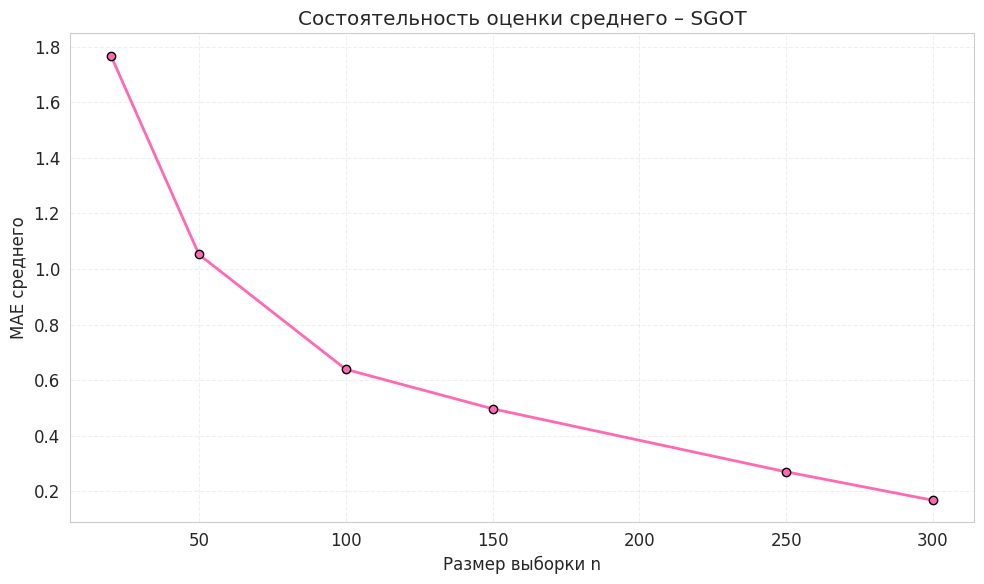

In [ ]:
cons_s = consistency_experiment(sgot)

plt.plot(cons_s["n"], cons_s["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

<a id="hypothesis-testing"></a>
## Hypothesis Testing — Alcohol consumption and Gamma-GT

В описании BUPA/UCI исторически использовалось разделение `drinks` по порогу **5 эквивалентов половины пинты в день**. В данной работе мы используем этот порог только для формирования двух групп потребления алкоголя:
- группа 1: `drinks <= 5`;
- группа 2: `drinks > 5`.



In [ ]:
low_drinks = df.loc[df["drinks"] <= 5, "gammagt"]
high_drinks = df.loc[df["drinks"] > 5, "gammagt"]

group_table = pd.DataFrame({
    "drinks <= 5": [
        len(low_drinks), low_drinks.mean(), low_drinks.median(),
        low_drinks.quantile(0.25), low_drinks.quantile(0.75),
    ],
    "drinks > 5": [
        len(high_drinks), high_drinks.mean(), high_drinks.median(),
        high_drinks.quantile(0.25), high_drinks.quantile(0.75),
    ],
}, index=["n", "mean_GGT", "median_GGT", "Q1_GGT", "Q3_GGT"])

display(group_table)

,drinks <= 5,drinks > 5
n,257.0000,88.0000
mean_GGT,31.8171,57.1705
median_GGT,22.0000,42.0000
Q1_GGT,14.0000,23.0000
Q3_GGT,36.0000,70.0000


Проверяем гипотезу:

$H_0:$ распределение GGT одинаково в двух группах.

$H_1:$ распределения GGT различаются.

Поскольку GGT не нормален, используем непараметрический двусторонний критерий Манна–Уитни.

In [ ]:
mw = stats.mannwhitneyu(low_drinks, high_drinks, alternative="two-sided")

n1, n2 = len(low_drinks), len(high_drinks)
rank_biserial = 1 - (2 * mw.statistic) / (n1 * n2)

print(f"Mann–Whitney U = {mw.statistic:.1f}")
print(f"p-value = {mw.pvalue:.3e}")
print(f"rank-biserial correlation = {rank_biserial:.4f}")

Mann–Whitney U = 6539.0
p-value = 3.487e-09
rank-biserial correlation = 0.4217


Визуализируем различия:

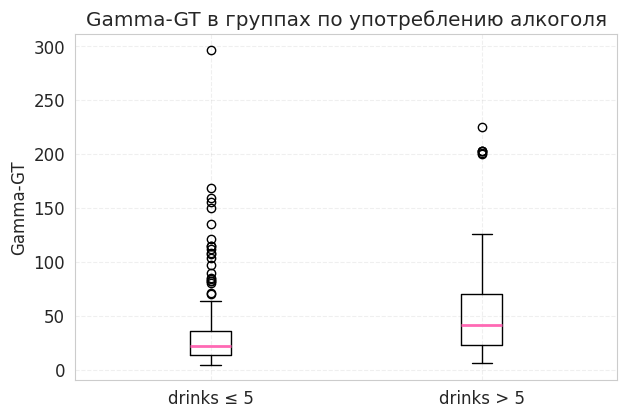

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.boxplot(
    [low_drinks, high_drinks],
    tick_labels=["drinks ≤ 5", "drinks > 5"],
    medianprops={'color': 'hotpink', 'linewidth': 2}
)
plt.ylabel("Gamma-GT")
plt.title("Gamma-GT в группах по употреблению алкоголя")
plt.grid(alpha=0.3, linestyle='--')
plt.show()

### Вывод по гипотезе:

- **Медианы:** В группе `drinks <= 5` медиана GGT составила ~22, а в группе `drinks > 5` — ~42.
- **Тест:** Критерий Манна–Уитни дал $p \approx 3.49 \cdot 10^{-9}$.
- **Решение:** При $\alpha = 0.05$ гипотеза $H_0$ ложна. Распределения GGT в двух группах значимо различаются.
- **Эффект:** Rank-biserial correlation $\approx 0.42$ указывает на заметный эффект при более высоких значениях GGT в группе с большим потреблением алкоголя.



<a id="Sampling Summary"></a>

## Sampling Summary
Сравнение совокупности и выборки:

Чтобы оценить, насколько хорошо случайная выборка объёмом $n=100$ представляет исходную совокупность ($N=345$), сравним их ключевые параметры: среднее значение и медиану для каждой из трёх выбранных величин.

Также рассчитаем абсолютную ошибку среднего (`abs_mean_error`), чтобы количественно оценить расхождение.

In [ ]:
sampling_summary = pd.DataFrame({
    "variable": ["drinks", "gammagt", "sgot"],
    "population_mean": [drinks.mean(), gammagt.mean(), sgot.mean()],
    "sample_mean": [
        sample_without["drinks"].mean(),
        sample_without["gammagt"].mean(),
        sample_without["sgot"].mean()
    ],
    "population_median": [drinks.median(), gammagt.median(), sgot.median()],
    "sample_median": [
        sample_without["drinks"].median(),
        sample_without["gammagt"].median(),
        sample_without["sgot"].median()
    ]
})

sampling_summary["abs_mean_error"] = (
    sampling_summary["sample_mean"] - sampling_summary["population_mean"]
).abs()

display(sampling_summary.round(4))

,variable,population_mean,sample_mean,population_median,sample_median,abs_mean_error
0,drinks,3.4551,3.6900,3.0000,3.0000,0.2349
1,gammagt,38.2841,40.4500,25.0000,25.0000,2.1659
2,sgot,24.6435,25.5500,23.0000,24.5000,0.9065


#### Интерпретация результатов:

- Абсолютная ошибка среднего невелика (от $\approx 0.23$ для `drinks` до $\approx 2.17$ для `gammagt`).
- Медианы выборки также очень близки к медианам генеральной совокупности (например, для `sgot` разница составляет всего 1.5 единицы).

**Вывод:** Случайная выборка объёмом $n=100$ хорошо отражает параметры исходной совокупности. Что служит иллюстрацией **"закона больших чисел"**: при достаточно большом $n$ выборочные оценки сходятся к параметрам генеральной совокупности.

<a id="lab-resume-1"></a>

## Lab resume

### 1. Датасет

- **BUPA Liver Disorders** (UCI), 345 наблюдений, 7 полей, пропусков нет.
- Обнаружено **4 полных дубликата**

### 2. Выбранные случайные величины

| Величина | Тип | Ключевое свойство |
|----------|-----|-------------------|
| `drinks` | дискретная | 16 уровней (0…20), правосторонняя асимметрия |
| `gammagt` | непрерывная | сильная правосторонняя асимметрия (skewness ≈ 2.87), не нормальна |
| `sgot` | непрерывная | правосторонняя асимметрия, не нормальна |

### 3. Проверка гипотезы: Alcohol consumption ↔ Gamma-GT

- Группы: `drinks ≤ 5` (n=257) vs `drinks > 5` (n=88).
- Медианы GGT: **22** против **42**.
- Критерий Манна–Уитни: $p \approx 3.49 \cdot 10^{-9} \ll 0.05$ → $H_0$ ложна.
- Rank-biserial correlation ≈ **0.42** — заметный эффект.

### 4. Выборка и состоятельность

- Случайная выборка $n=100$ без возвращения хорошо отражает совокупность $N=345$.
- Абсолютная ошибка среднего: от ≈0.23 (`drinks`) до ≈2.17 (`gammagt`).
- Эмпирически подтверждена **состоятельность** оценок среднего и дисперсии: MAE убывает с ростом $n$.

### 5. Методы

- **EDA**: описательные статистики, гистограммы, boxplot, ECDF.
- **Нормальность**: Q-Q plot, Shapiro-Wilk, логарифмическое преобразование.
- **Аппроксимация**: подбор распределений (AIC), лучший fit для GGT — Lognormal.
- **Нормализация**: Z-standartization и Min-Max.
- **Независимость**: scatter plots, коэффициенты Пирсона и Спирмена.
- **Состоятельность**: эксперимент с ростом объёма выборки.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| DATA | current notebook | — | описание датасета и корректная интерпретация selector |
| RV | current notebook | — | 3 случайные величины и стохастическая природа |
| EDA | current notebook | — | описательные статистики, PMF, ECDF, гистограммы |
| NORM | current notebook | — | Z-standardization и Min-Max |
| DEP | current notebook | — | Pearson и Spearman для трёх пар |
| SAMPLE | current notebook | — | выборка с/без возвращения |
| CONS | current notebook | — | эмпирическая состоятельность оценок |
| HYP | current notebook | — | Mann–Whitney для drinks и Gamma-GT |

> Численные коэффициенты `coeff` в предоставленном условии не заданы, поэтому они не выдумываются.